In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
lsoa_data_path = Path("Data/regression/lsoa_dataset_complete.gpkg")
lsoa_data = gpd.read_file(lsoa_data_path, engine="pyogrio")

In [3]:
lsoa_data

,LSOA21CD,LSOA21NM,GlobalID,area_km2,accommodation_eating_and_drinking_density,attractions_density,commercial_services_density,education_and_health_density,manufacturing_and_production_density,public_infrastructure_density,...,IMD Decile,Income Rank,Income Decile,Employment Rank,Employment Decile,intersection_density,crime_density,crime_rate_1000,pop_density,geometry
0,E01014370,Bath and North East Somerset 007A,{4803A59D-E95B-4FE6-BEB0-E69E84BD7D48},0.377030,572.898314,106.092280,681.642902,137.919965,106.092280,204.227640,...,3,13023,4,12849,4,230.750710,11855.812338,2314.862765,5121.604838,"MULTIPOLYGON (((375292.289 165633.714, 375288...."
1,E01014371,Bath and North East Somerset 007B,{9C5F2B67-06C6-477C-83FF-A8DEFC8C184F},0.409491,144.081440,70.819691,166.059964,29.304700,19.536466,131.871148,...,5,26693,8,22402,7,139.197323,7406.762825,1402.219140,5282.172104,"MULTIPOLYGON (((375624.781 165202.406, 375619...."
2,E01014372,Bath and North East Somerset 007C,{34817845-639D-4BDC-85F2-3650D6948257},0.166801,317.742958,143.883604,743.398618,149.878754,101.917553,77.936952,...,5,23396,7,21101,7,161.869054,12607.800761,1110.348469,11354.814380,"MULTIPOLYGON (((375327.102 165666.338, 375313...."
3,E01014373,Bath and North East Somerset 010A,{CF46DDA7-D5D4-4F32-883D-D6813023538C},1.059979,3.773658,1.886829,19.811705,5.660487,3.773658,16.038047,...,7,18084,6,21237,7,37.736580,175.475098,118.471338,1481.160772,"MULTIPOLYGON (((377762.251 168340.474, 377738...."
4,E01014374,Bath and North East Somerset 010B,{9B5DFE41-266E-4AB9-813E-8592E3AC4BB0},5.002127,0.599745,0.000000,0.399830,0.399830,0.199915,6.197363,...,9,24108,8,25862,8,12.994471,25.189283,77.825818,323.662291,"MULTIPOLYGON (((378818.843 167715.55, 378817.4..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3402,E01035229,South Gloucestershire 035C,{FFCFBCDA-4686-4F28-BCB2-87F483316D15},0.580155,10.342064,1.723677,24.131482,10.342064,10.342064,29.302514,...,8,27874,9,32746,10,149.959922,605.010720,104.278075,5801.897678,"MULTIPOLYGON (((362036.795 178559.778, 362035...."
3403,E01035230,South Gloucestershire 035D,{75AF98C1-D8D9-4FA8-8123-12C67DF32C60},0.632230,12.653614,6.326807,7.908509,0.000000,0.000000,14.235316,...,10,21421,7,29740,9,158.170174,925.295520,405.405405,2282.395616,"MULTIPOLYGON (((361548.098 178707.611, 361546 ..."
3404,E01035231,South Gloucestershire 035E,{FFE85EA9-855F-4746-B64D-7DA442E1FEAB},0.440986,0.000000,6.802944,6.802944,2.267648,0.000000,6.802944,...,10,31495,10,33594,10,106.579458,346.950150,105.882353,3276.751420,"MULTIPOLYGON (((361922.063 177801.938, 361918...."
3405,E01035232,South Gloucestershire 036B,{17EEB482-0456-4254-926A-BCA01EA1C8E3},0.652123,7.667270,9.200723,30.669078,7.667270,0.000000,29.135624,...,7,14296,5,18580,6,174.813746,860.267647,262.763466,3273.924110,"MULTIPOLYGON (((363286 179964, 363286 179978, ..."


In [4]:
# To make it easier to understand, it's better to divide the parameters into some groups, like POI groups & others

In [5]:
poi_vars = [
    "accommodation_eating_and_drinking_density",
    "attractions_density",
    "commercial_services_density",
    "education_and_health_density",
    "manufacturing_and_production_density",
    "public_infrastructure_density",
    "retail_density",
    "sport_and_entertainment_density",
    "transport_density"
]

other_vars = [
    "intersection_density",
    "urban_part",
    "suburban_part",
    "rural_part",
    "pop_density",
    "Income Rank",
    "Employment Rank",
    "crime_density"
]

In [6]:
lsoa_data_table = lsoa_data.copy()
lsoa_data_table = lsoa_data_table[poi_vars+other_vars]

In [7]:
# Function to generate distributions histograms

In [8]:
from scipy.stats import skew

def plot_distributions(
    df,
    poi_vars,
    other_vars,
    bins=30,
    kde=True,
    ncols=3,
    figsize_width=14,
    row_height=3.2
):
    poi_rows = int(np.ceil(len(poi_vars) / ncols))
    other_rows = int(np.ceil(len(other_vars) / ncols))

    fig = plt.figure(
        figsize=(
            figsize_width,
            row_height * (poi_rows + other_rows)
        )
    )

    # Grid management
    outer = fig.add_gridspec(
        nrows=2,
        ncols=1,
        height_ratios=[poi_rows, other_rows],
        hspace=0.20
    )

    # POI subplot grid
    poi_grid = outer[0].subgridspec(
        poi_rows,
        ncols,
        hspace=0.45,
        wspace=0.25
    )

    # Other variables subplot grid
    other_grid = outer[1].subgridspec(
        other_rows,
        ncols,
        hspace=0.45,
        wspace=0.25
    )

    def plot_hist(ax, var, xlabel=None):
        data = df[var].dropna()

        sns.histplot(
            data,
            bins=bins,
            kde=kde,
            ax=ax
        )

        skewness = skew(data)

        ax.set_title(
            var.replace("_", " ").title(),
            fontsize=10
        )

        ax.set_xlabel(
            xlabel or var.replace("_", " ").title()
        )

        ax.set_ylabel("Number of LSOAs")

        ax.text(
            0.95,
            0.90,
            f"Skew = {skewness:.2f}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=8,
            bbox=dict(
                boxstyle="round",
                facecolor="#D3D3D3",
                alpha=0.8
            )
        )

    # POI variables

    poi_axes = []

    for i in range(poi_rows * ncols):
        row = i // ncols
        col = i % ncols

        ax = fig.add_subplot(poi_grid[row, col])
        poi_axes.append(ax)

        if i < len(poi_vars):
            plot_hist(
                ax,
                poi_vars[i],
                xlabel="Density"
            )
        else:
            ax.axis("off")

    # Other variables

    other_axes = []

    for i in range(other_rows * ncols):
        row = i // ncols
        col = i % ncols

        ax = fig.add_subplot(other_grid[row, col])
        other_axes.append(ax)

        if i < len(other_vars):
            plot_hist(
                ax,
                other_vars[i]
            )
        else:
            ax.axis("off")

    # Section headings

    # Get actual positions from subplot grids
    poi_top = max(ax.get_position().y1 for ax in poi_axes)
    other_top = max(ax.get_position().y1 for ax in other_axes)

    fig.text(
        0.5,
        poi_top + 0.025,
        "POI Group Variables",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold"
    )

    fig.text(
        0.5,
        other_top + 0.025,
        "Other Variables",
        ha="center",
        va="bottom",
        fontsize=16,
        fontweight="bold"
    )

    return fig, (poi_axes, other_axes)

In [9]:
# Function to save a figure

In [10]:
def save_fig(fig, filename, folder="Figures", dpi=300):

    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)

    filepath = folder / f"{filename}.png"

    fig.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight"
    )

    print(f"Figure saved to: {filepath}")

Figure saved to: Figures\hist_original.png


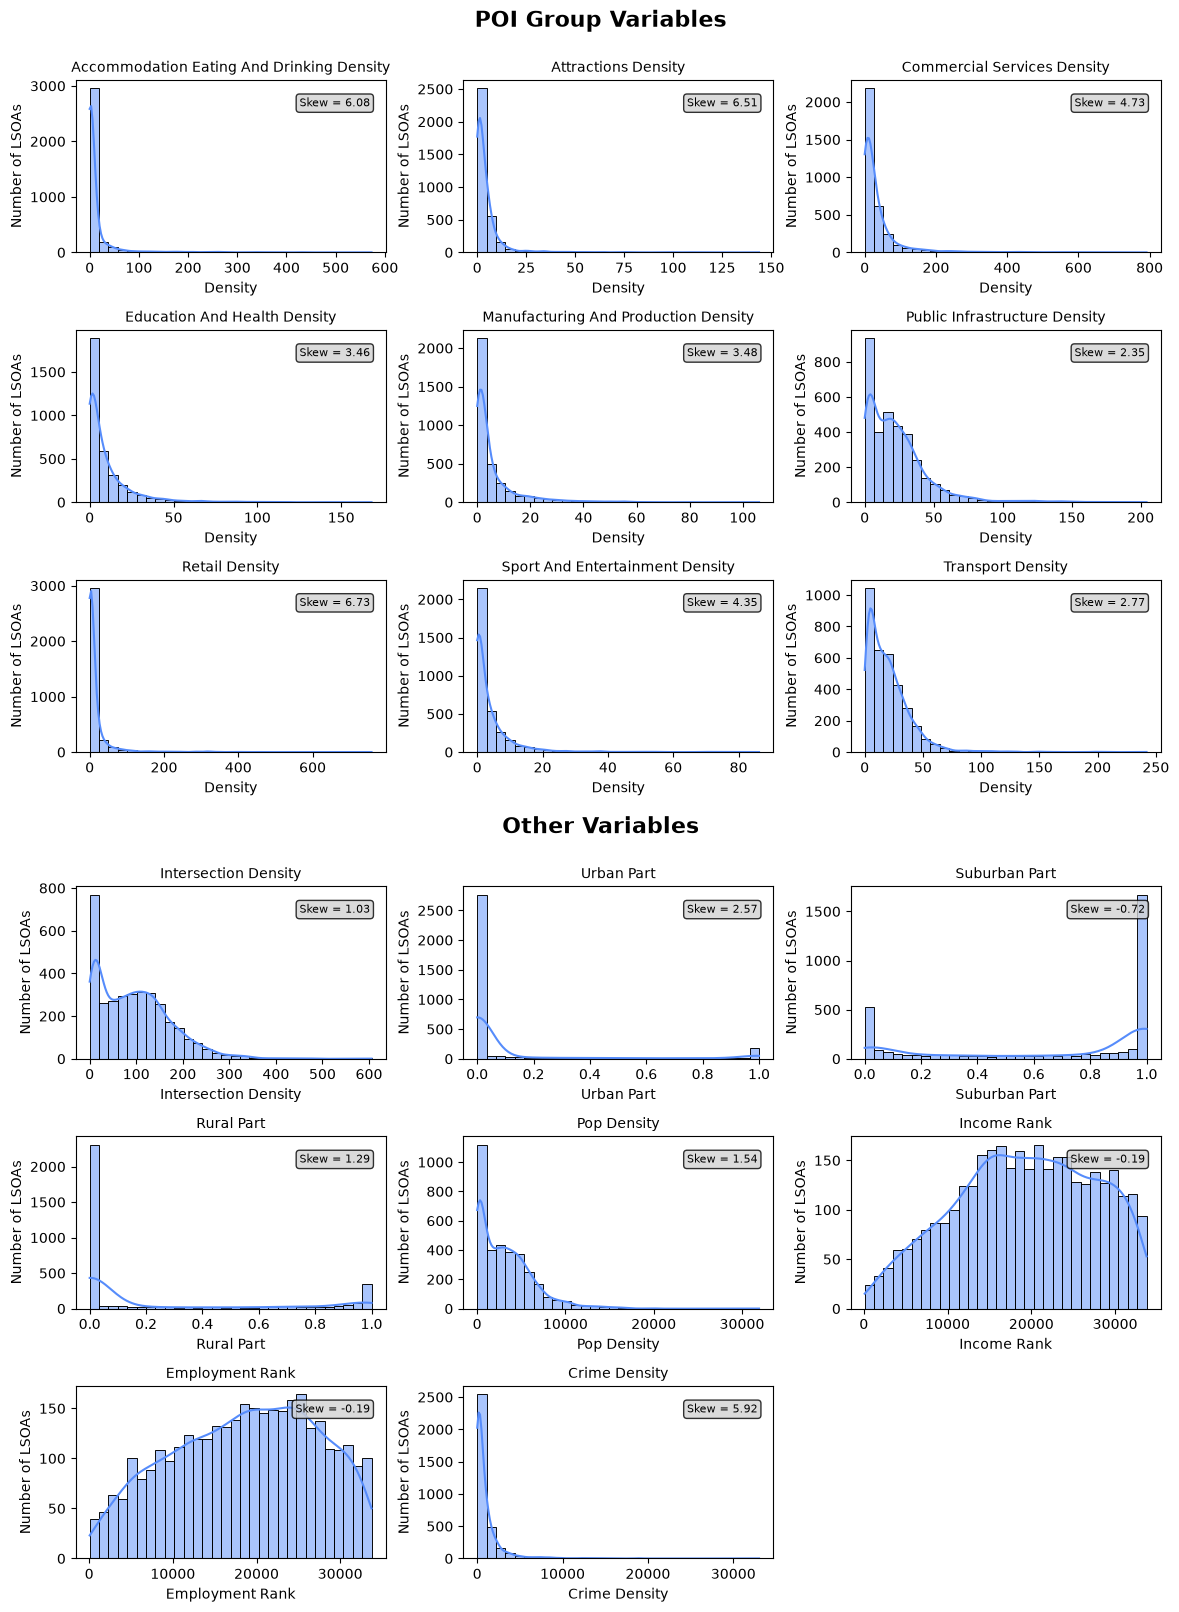

In [11]:
fig, axes = plot_distributions(
    lsoa_data,
    poi_vars,
    other_vars
)

save_fig(fig, "hist_original")

plt.show()

In [12]:
# Variables that have high positive and negative skew (< -2 or > 2) should be transformed to normalize the distribution
# POI Group variables, crime_density & urban_part all have high skewness, but will transform POI Groups & crime_density
# As urban_part does not have that high skew, also it comes with other two proportions (suburban & rural).

In [13]:
lsoa_data_transformed = lsoa_data.copy()

In [14]:
for var in poi_vars:
    lsoa_data_transformed[f"log_{var}"] = np.log1p(
        lsoa_data_transformed[var]
    )

In [15]:
lsoa_data_transformed["log_crime_density"] = np.log1p(
    lsoa_data_transformed["crime_density"]
)

In [16]:
lsoa_data_transformed.columns

Index(['LSOA21CD', 'LSOA21NM', 'GlobalID', 'area_km2',
       'accommodation_eating_and_drinking_density', 'attractions_density',
       'commercial_services_density', 'education_and_health_density',
       'manufacturing_and_production_density', 'public_infrastructure_density',
       'retail_density', 'sport_and_entertainment_density',
       'transport_density', 'intersection_count', 'crime_count', 'total_pop',
       '65+_pop', 'urban_part', 'suburban_part', 'rural_part', 'IMD Rank',
       'IMD Decile', 'Income Rank', 'Income Decile', 'Employment Rank',
       'Employment Decile', 'intersection_density', 'crime_density',
       'crime_rate_1000', 'pop_density', 'geometry',
       'log_accommodation_eating_and_drinking_density',
       'log_attractions_density', 'log_commercial_services_density',
       'log_education_and_health_density',
       'log_manufacturing_and_production_density',
       'log_public_infrastructure_density', 'log_retail_density',
       'log_sport_and_entert

In [17]:
poi_vars = [
    "log_accommodation_eating_and_drinking_density",
    "log_attractions_density",
    "log_commercial_services_density",
    "log_education_and_health_density",
    "log_manufacturing_and_production_density",
    "log_public_infrastructure_density",
    "log_retail_density",
    "log_sport_and_entertainment_density",
    "log_transport_density"
]

other_vars = [
    "intersection_density",
    "log_crime_density",
    "pop_density",
    "Income Rank",
    "Employment Rank",
    "urban_part",
    "suburban_part",
    "rural_part"
]

Figure saved to: Figures\hist_transformed.png


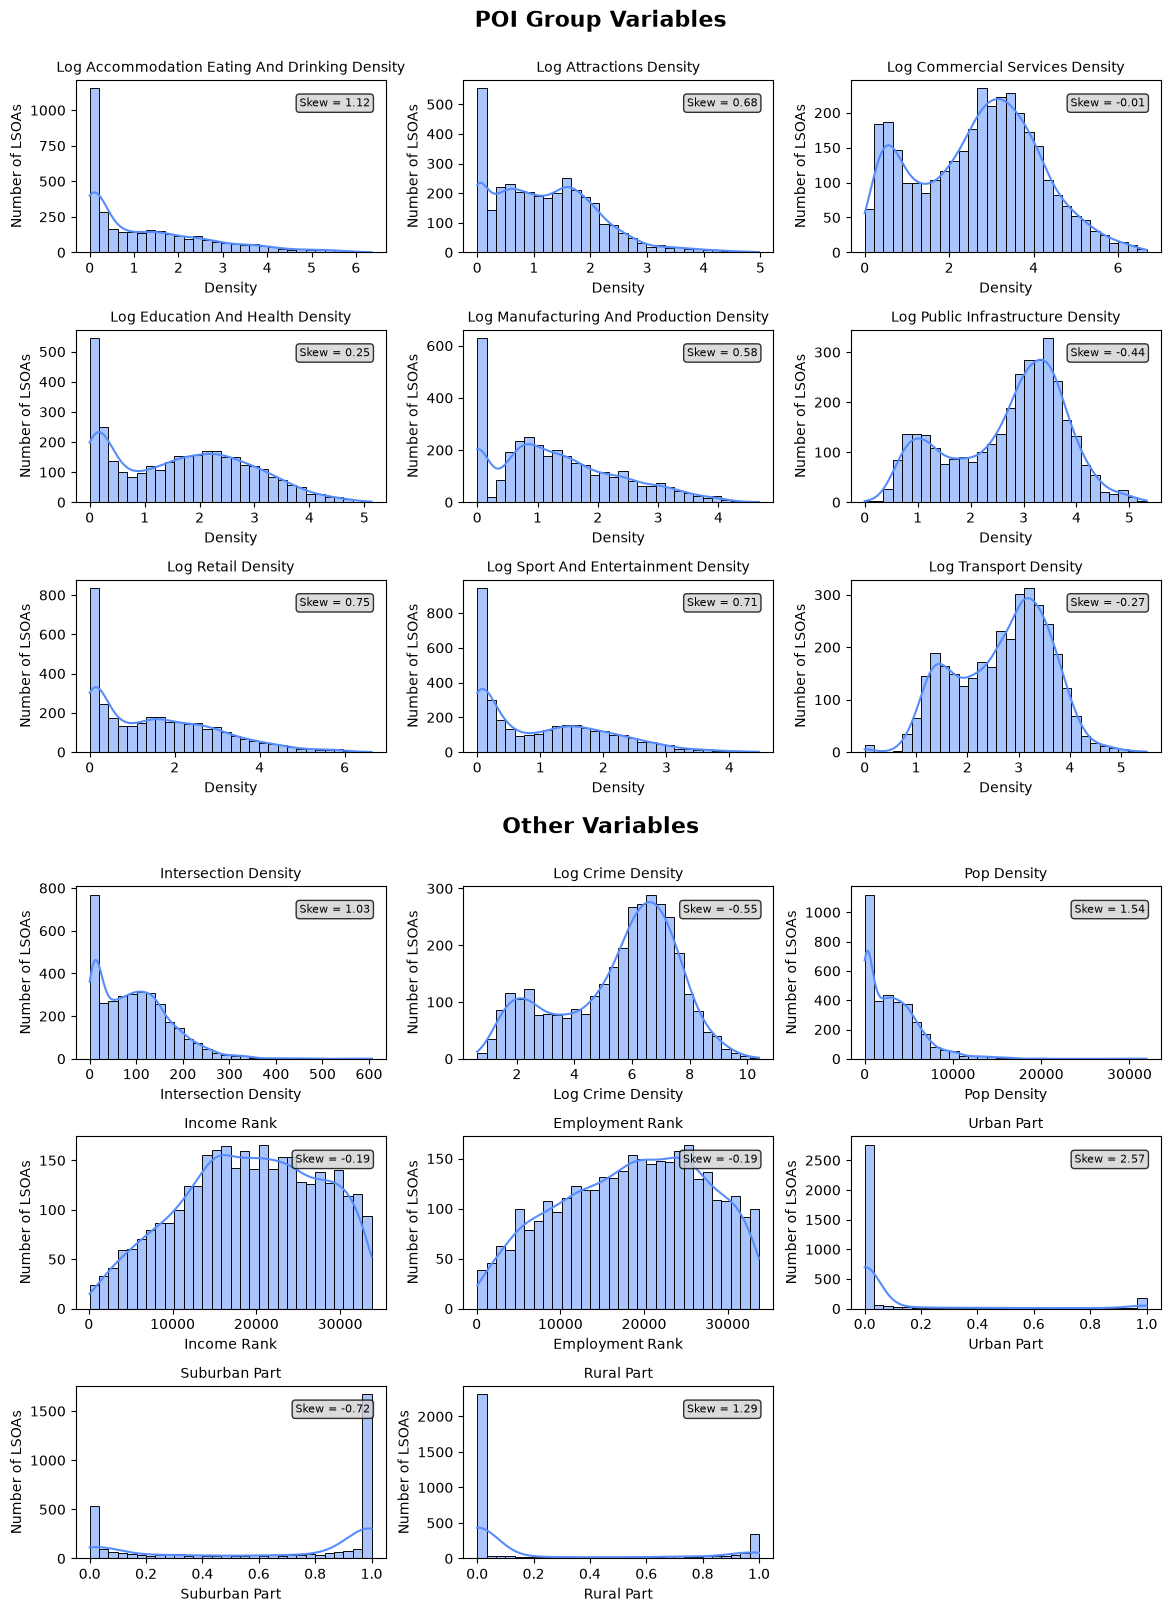

In [18]:
fig, axes = plot_distributions(
    lsoa_data_transformed,
    poi_vars,
    other_vars
)

save_fig(fig, "hist_transformed")

plt.show()

In [19]:
# Correlation Analysis (Pearson's Correlation & VIF)

In [20]:
predictor_vars = [
    "log_accommodation_eating_and_drinking_density",
    "log_attractions_density",
    "log_commercial_services_density",
    "log_education_and_health_density",
    "log_manufacturing_and_production_density",
    "log_public_infrastructure_density",
    "log_retail_density",
    "log_sport_and_entertainment_density",
    "log_transport_density",

    "intersection_density",
    "pop_density",
    "Income Rank",
    "Employment Rank",
    "urban_part",
    "suburban_part",
    "rural_part"
]

Figure saved to: Figures\corr_mat1.png


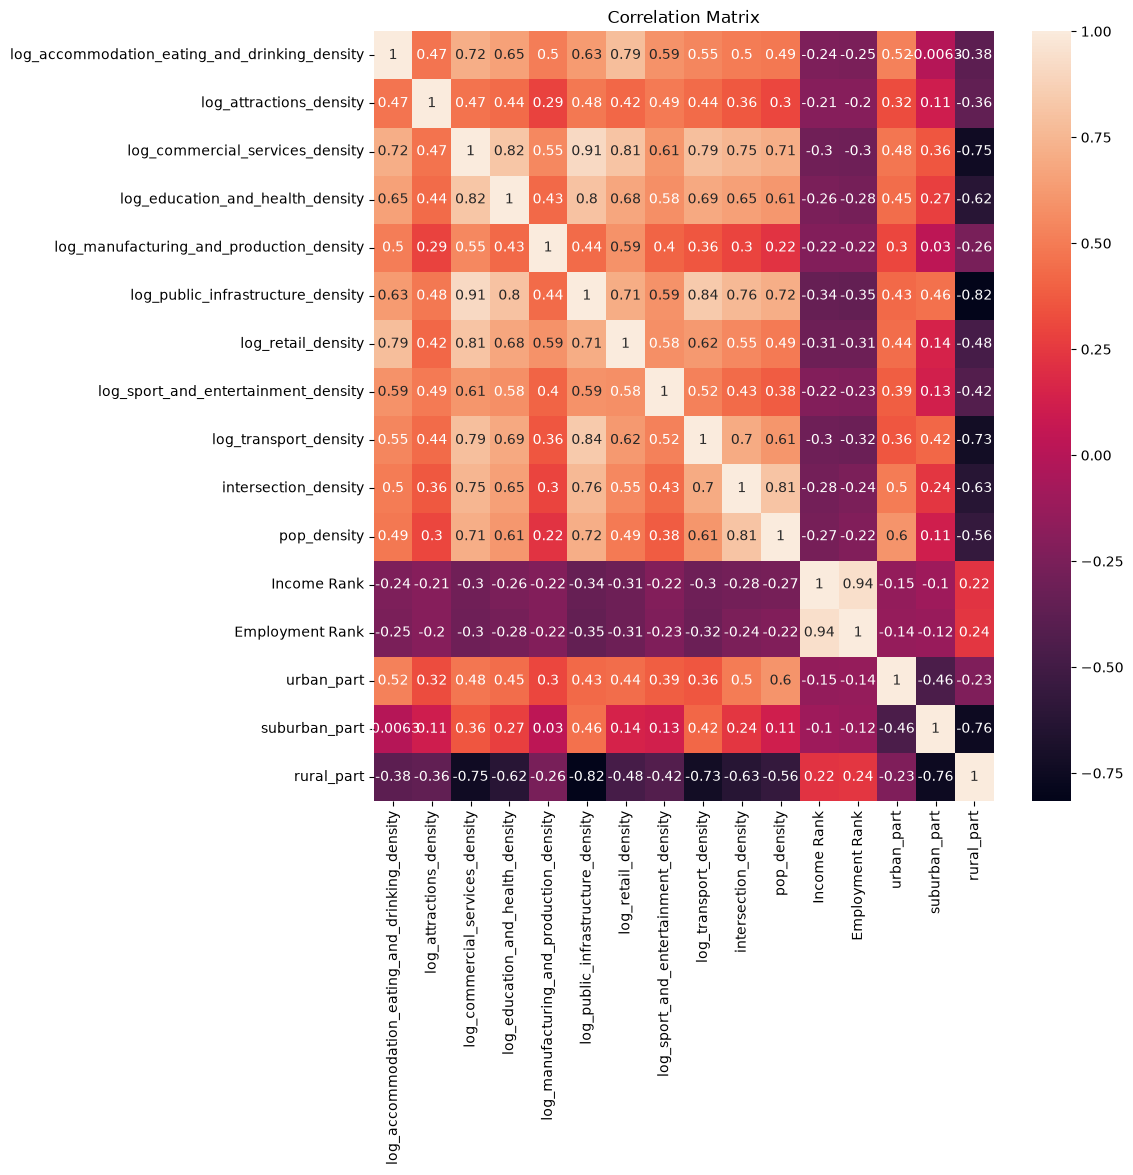

In [21]:
correlation_matrix = lsoa_data_transformed[predictor_vars].corr()

# set figure size
fig, ax = plt.subplots(figsize=(10,10))

# plot correlation matrix
sns.heatmap(correlation_matrix, annot=True, ax=ax)

# set the title
ax.set_title('Correlation Matrix')

save_fig(fig, "corr_mat1")

In [22]:
# VIF (to check multicollinearity)

In [23]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data, variables):

    X = data[variables].dropna().copy()
    X = sm.add_constant(X)

    vif = pd.DataFrame({
        "feature": X.columns,
        "VIF": [
            variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])
        ]
    })

    return (
        vif[vif["feature"] != "const"]
        .sort_values("VIF", ascending=False)
        .reset_index(drop=True)
    )

In [24]:
calculate_vif(lsoa_data_transformed, predictor_vars)

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,feature,VIF
0,rural_part,inf
1,urban_part,inf
2,suburban_part,inf
3,log_commercial_services_density,11.786591
4,log_public_infrastructure_density,10.465489
5,Income Rank,9.521196
6,Employment Rank,9.492169
7,log_retail_density,4.518042
8,pop_density,4.351396
9,intersection_density,3.912615


In [25]:
# From the correlation matrix, the Income Rank & Employment Rank have very high correlations, so Employment Rank will be removed from the predictors list.
# The VIF result is as expected; if we sum the three macro groups of Spatial Signatures proportions, it will equal to 1, means perfect multicollinearity
# So one of the columns have to go, the rural_part will be excluded
# From the POI groups, log_public_infrastructure_density & log_commercial_services_density have high VIF and correlation
# commercial services will be excluded

In [26]:
predictor_vars2 = [
    "log_accommodation_eating_and_drinking_density",
    "log_attractions_density",
    "log_education_and_health_density",
    "log_manufacturing_and_production_density",
    "log_public_infrastructure_density",
    "log_retail_density",
    "log_sport_and_entertainment_density",
    "log_transport_density",

    "intersection_density",
    "pop_density",
    "Income Rank",
    "urban_part",
    "suburban_part",
    # "rural_part"
]

In [27]:
# VIF

In [28]:
calculate_vif(lsoa_data_transformed, predictor_vars2)

,feature,VIF
0,log_public_infrastructure_density,9.369238
1,urban_part,4.334786
2,suburban_part,4.251907
3,pop_density,4.021358
4,intersection_density,3.858763
5,log_retail_density,3.752356
6,log_transport_density,3.659813
7,log_accommodation_eating_and_drinking_density,3.321025
8,log_education_and_health_density,3.260284
9,log_sport_and_entertainment_density,1.934978


In [29]:
# Corr matrix

Figure saved to: Figures\corr_mat2.png


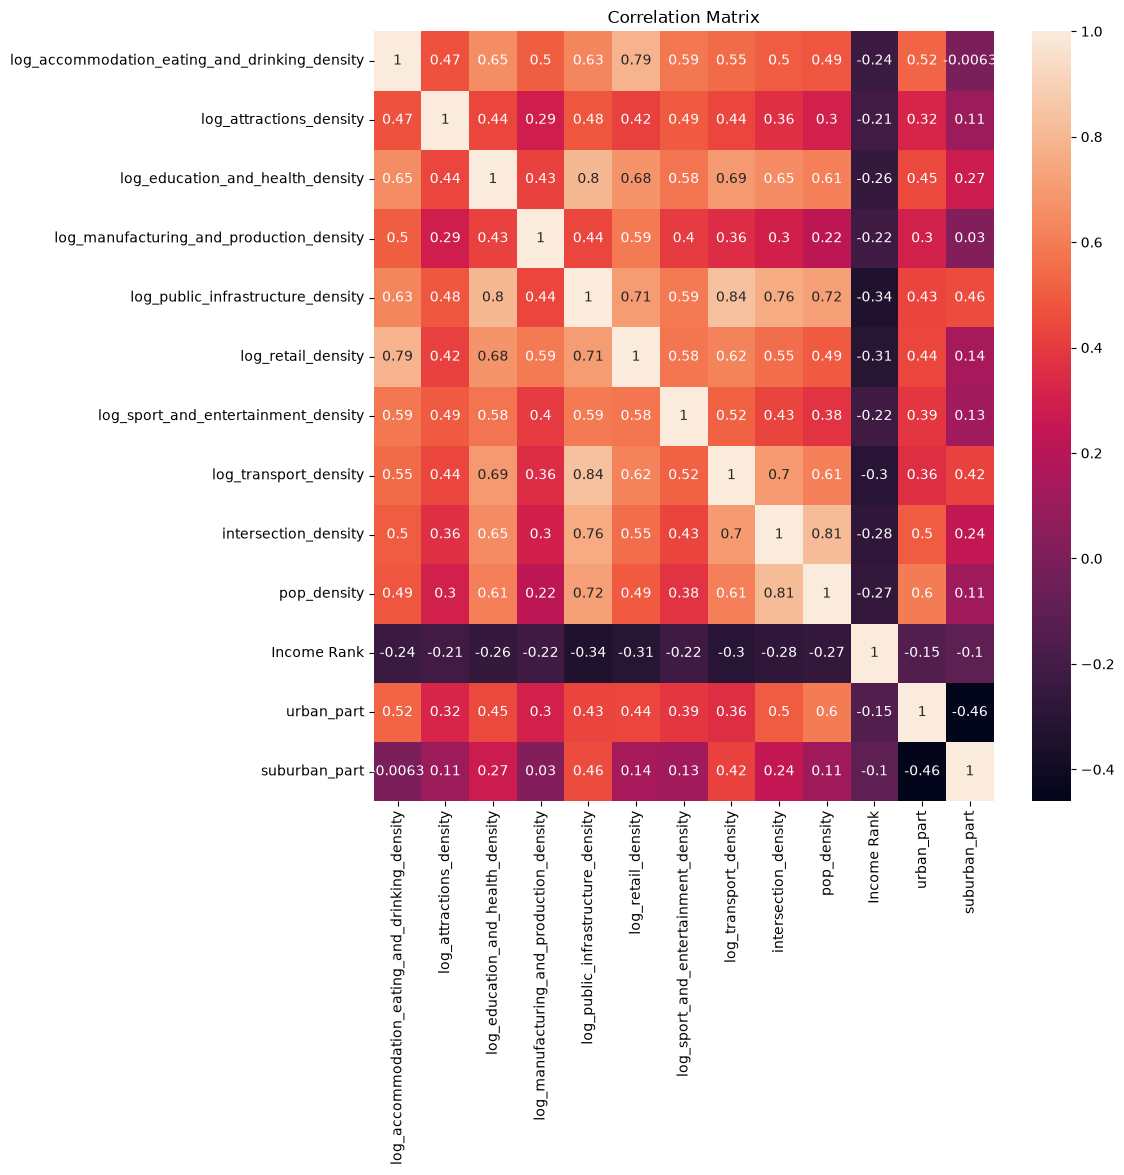

In [30]:
correlation_matrix = lsoa_data_transformed[predictor_vars2].corr()

# set figure size
fig, ax = plt.subplots(figsize=(10,10))

# plot correlation matrix
sns.heatmap(correlation_matrix, annot=True, ax=ax)

# set the title
ax.set_title('Correlation Matrix')

save_fig(fig, 'corr_mat2')
plt.show()

In [31]:
# With the public infrastructure variable included, the corr matrix and VIF is still a bit high, so will consider dropping it.

In [32]:
predictor_vars3 = [
    "log_accommodation_eating_and_drinking_density",
    "log_attractions_density",
    "log_education_and_health_density",
    "log_manufacturing_and_production_density",
    # "log_public_infrastructure_density",
    "log_retail_density",
    "log_sport_and_entertainment_density",
    "log_transport_density",

    "intersection_density",
    "pop_density",
    "Income Rank",
    "urban_part",
    "suburban_part",
    # "rural_part"
]

In [33]:
calculate_vif(lsoa_data_transformed, predictor_vars3)

,feature,VIF
0,urban_part,3.937641
1,intersection_density,3.834087
2,pop_density,3.782576
3,log_retail_density,3.678314
4,log_accommodation_eating_and_drinking_density,3.307756
5,log_transport_density,3.257106
6,suburban_part,3.064710
7,log_education_and_health_density,2.971205
8,log_sport_and_entertainment_density,1.905026
9,log_manufacturing_and_production_density,1.614370


Figure saved to: Figures\corr_mat3.png


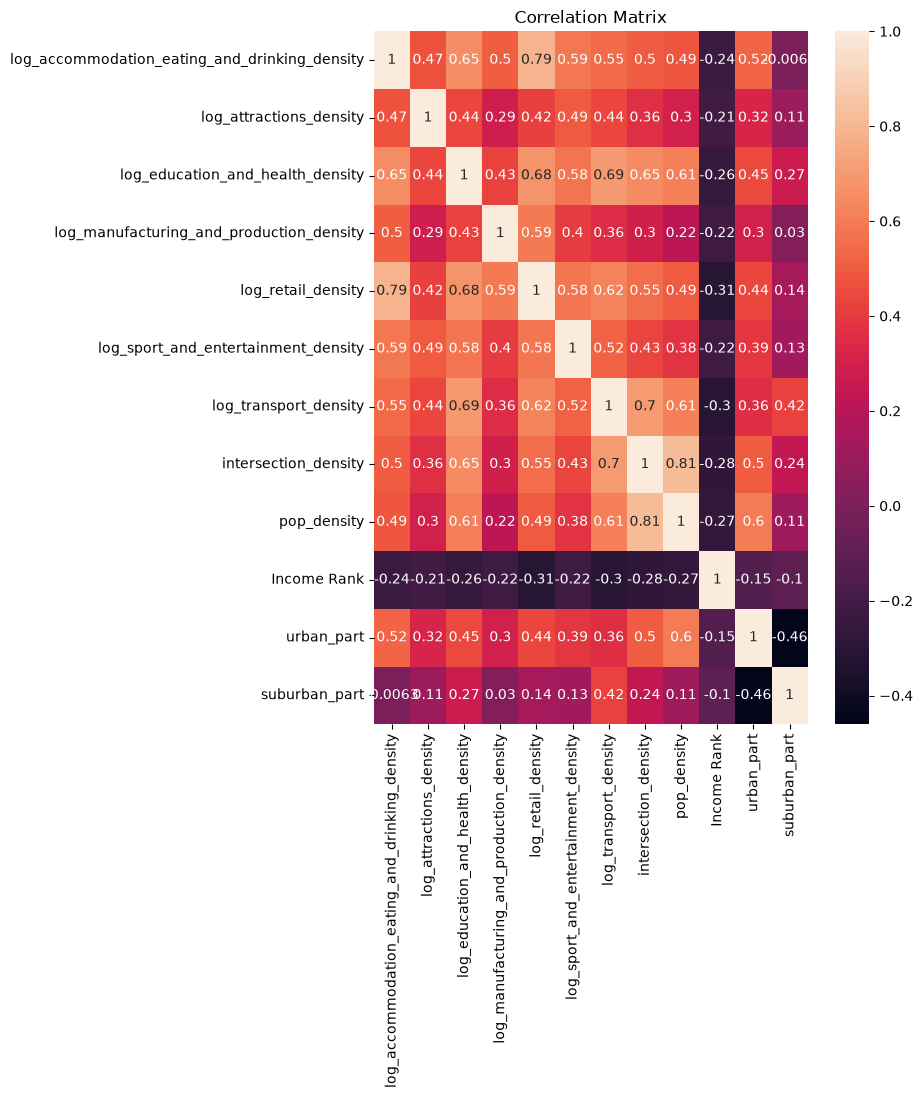

In [34]:
correlation_matrix = lsoa_data_transformed[predictor_vars3].corr()

# set figure size
fig, ax = plt.subplots(figsize=(7,9))

# plot correlation matrix
sns.heatmap(correlation_matrix, annot=True, ax= ax)

# set the title
ax.set_title('Correlation Matrix')

save_fig(fig, 'corr_mat3')

plt.show()

In [35]:
# The result of VIF and Correlation Matrix of the final combination of predictors are quite good,
# So this variables combination will be used to the modelling phase.

In [36]:
# Spatial Dependence / Global Moran's I

In [37]:
#from .autonotebook import tqdm as notebook_tqdm
from libpysal.weights import Queen, KNN
from esda.moran import Moran

from spreg import OLS, ML_Lag, ML_Error

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [38]:
lsoa_data_transformed.geometry.is_empty.unique() # no geometry data is empty/ invalid geometry

array([False])

In [39]:
# Create Queen contiguity weights

In [40]:
w = Queen.from_dataframe(
    lsoa_data_transformed,
    ids=lsoa_data_transformed["LSOA21CD"].tolist(),
    use_index=False
)

# Row-standardise
w.transform = "R"

print("Number of LSOAs:", w.n)
print("Islands:", w.islands)
print("Mean neighbours:", w.mean_neighbors)

('WARNING: ', 'E01019077', ' is an island (no neighbors)')
Number of LSOAs: 3407
Islands: ['E01019077']
Mean neighbours: 5.600234810683886


C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\libpysal\weights\contiguity.py:354: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: E01019077.
  W.__init__(self, neighbors, ids=ids, **kw)


In [41]:
# There is one island separated from the main body/continent, which is Isle of Scilly.

# It's safe to drop that, because it's 1/3407 (0.03%) of study area

       LSOA21CD              LSOA21NM
1465  E01019077  Isles of Scilly 001A


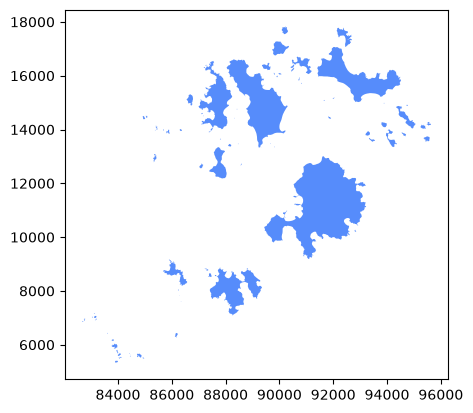

In [42]:
island = lsoa_data[
    lsoa_data["LSOA21CD"] == "E01019077"
]

island.plot() # Isle of Scilly

print(island[
    ["LSOA21CD", "LSOA21NM"]
])

In [43]:
lsoa_data_connected = lsoa_data_transformed.copy()
lsoa_data_connected = lsoa_data_transformed[lsoa_data_transformed["LSOA21CD"] != "E01019077"]

In [44]:
# After removing the separated island, we'll recalculate the queen contiguity weights

In [45]:
# Create spatial weights (Queen contiguity weights)

w2 = Queen.from_dataframe(
    lsoa_data_connected,
    ids="LSOA21CD"
)

# Row-standardise
w2.transform = "R"

print("Number of LSOAs:", w2.n)
print("Islands:", w2.islands)
print("Mean neighbours:", w2.mean_neighbors)

Number of LSOAs: 3406
Islands: []
Mean neighbours: 5.601879036993541


In [46]:
y = lsoa_data_connected["log_crime_density"].values.reshape(-1,1)

moran = Moran(
    y,
    w2,
    permutations=999
)

print(f"Moran's I: {moran.I:.4f}")
print(f"Expected I: {moran.EI:.4f}")
print(f"Permutation p-value: {moran.p_sim:.4f}")
print(f"z-score: {moran.z_sim:.4f}")

Moran's I: 0.7269
Expected I: -0.0003
Permutation p-value: 0.0010
z-score: 66.8844


In [47]:
import contextily as ctx

from esda.moran import Moran_Local

# Dependent variable
y = lsoa_data_connected["log_crime_density"].values

# Local Moran's I
lisa = Moran_Local(
    y,
    w2,
    permutations=999,
    seed=42
)

# Create Cluster Variable
lsoa_data_connected["lisa_cluster"] = "Not Significant"

# Significant observations
sig = lisa.p_sim < 0.05

# Assign cluster types
lsoa_data_connected.loc[sig & (lisa.q == 1), "lisa_cluster"] = "High-High"
lsoa_data_connected.loc[sig & (lisa.q == 2), "lisa_cluster"] = "Low-High"
lsoa_data_connected.loc[sig & (lisa.q == 3), "lisa_cluster"] = "Low-Low"
lsoa_data_connected.loc[sig & (lisa.q == 4), "lisa_cluster"] = "High-Low"

In [48]:
print(lsoa_data_connected["lisa_cluster"].value_counts())

lisa_cluster
Not Significant    1980
Low-Low             766
High-High           621
High-Low             36
Low-High              3
Name: count, dtype: int64


In [49]:
from matplotlib.patches import Patch
from shapely.ops import unary_union

# create boundary lines

sw_bound = lsoa_data[['geometry']].dissolve()

sw_bound_lines = sw_bound[['geometry']].dissolve()

sw_bound_outline = unary_union(sw_bound_lines.geometry)

In [50]:
lsoa_data_connected.columns

Index(['LSOA21CD', 'LSOA21NM', 'GlobalID', 'area_km2',
       'accommodation_eating_and_drinking_density', 'attractions_density',
       'commercial_services_density', 'education_and_health_density',
       'manufacturing_and_production_density', 'public_infrastructure_density',
       'retail_density', 'sport_and_entertainment_density',
       'transport_density', 'intersection_count', 'crime_count', 'total_pop',
       '65+_pop', 'urban_part', 'suburban_part', 'rural_part', 'IMD Rank',
       'IMD Decile', 'Income Rank', 'Income Decile', 'Employment Rank',
       'Employment Decile', 'intersection_density', 'crime_density',
       'crime_rate_1000', 'pop_density', 'geometry',
       'log_accommodation_eating_and_drinking_density',
       'log_attractions_density', 'log_commercial_services_density',
       'log_education_and_health_density',
       'log_manufacturing_and_production_density',
       'log_public_infrastructure_density', 'log_retail_density',
       'log_sport_and_entert

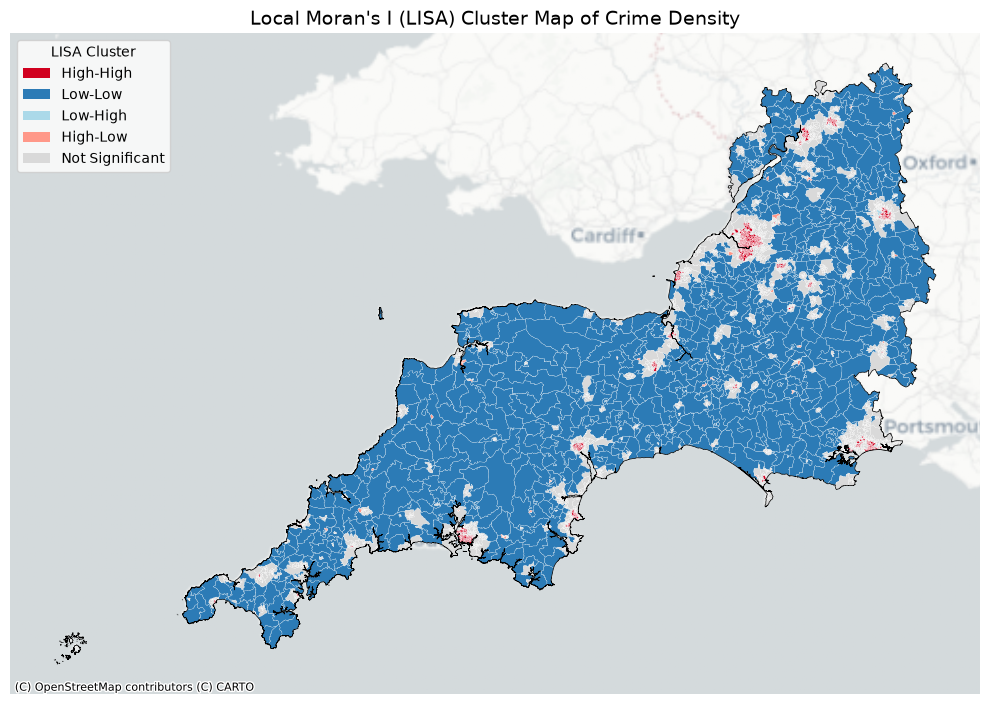

In [51]:
lisa_map = lsoa_data_connected.to_crs(epsg=27700)

cluster_colors = {
    "High-High": "#d1001f",
    "Low-Low": "#2c7bb6",
    "Low-High": "#abd9e9",
    "High-Low": "#ff9889",
    "Not Significant": "#d9d9d9"
}

lsoa_data_connected["lisa_color"] = (
    lsoa_data_connected["lisa_cluster"].map(cluster_colors)
)

legend_elements = [
    Patch(facecolor="#d1001f", label="High-High"),
    Patch(facecolor="#2c7bb6", label="Low-Low"),
    Patch(facecolor="#abd9e9", label="Low-High"),
    Patch(facecolor="#ff9889", label="High-Low"),
    Patch(facecolor="#d9d9d9", label="Not Significant")
]

fig, ax = plt.subplots(figsize=(10, 10))

lsoa_data_connected.plot(
    color=lsoa_data_connected["lisa_color"],
    edgecolor="white",
    linewidth=0.15,
    ax=ax
)

gpd.GeoSeries([sw_bound_outline], crs=sw_bound.crs).boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.5
)

ctx.add_basemap(
    ax,
    crs=lisa_map.crs,
    source=ctx.providers.CartoDB.Positron
    #attribution=False
)

ax.legend(
    handles=legend_elements,
    title="LISA Cluster",
    loc="upper left",
    frameon=True
)

ax.set_title(
    "Local Moran's I (LISA) Cluster Map of Crime Density",
    fontsize=14
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [52]:
save_fig(fig, "lisa_map")

Figure saved to: Figures\lisa_map.png


In [53]:
# OLS

In [54]:
# y = lsoa_data_connected["crime_density"]
# X = lsoa_data_connected[predictors_final]

In [55]:
predictor_vars4 = predictor_vars3 + ["log_public_infrastructure_density"]

In [56]:
lsoa_data_connected.columns

Index(['LSOA21CD', 'LSOA21NM', 'GlobalID', 'area_km2',
       'accommodation_eating_and_drinking_density', 'attractions_density',
       'commercial_services_density', 'education_and_health_density',
       'manufacturing_and_production_density', 'public_infrastructure_density',
       'retail_density', 'sport_and_entertainment_density',
       'transport_density', 'intersection_count', 'crime_count', 'total_pop',
       '65+_pop', 'urban_part', 'suburban_part', 'rural_part', 'IMD Rank',
       'IMD Decile', 'Income Rank', 'Income Decile', 'Employment Rank',
       'Employment Decile', 'intersection_density', 'crime_density',
       'crime_rate_1000', 'pop_density', 'geometry',
       'log_accommodation_eating_and_drinking_density',
       'log_attractions_density', 'log_commercial_services_density',
       'log_education_and_health_density',
       'log_manufacturing_and_production_density',
       'log_public_infrastructure_density', 'log_retail_density',
       'log_sport_and_entert

In [57]:
y = lsoa_data_connected["log_crime_density"]#.values.reshape(-1, 1)
X = lsoa_data_connected[predictor_vars3].values

In [58]:
ols = OLS(
    y,
    X,
    w=w2,
    spat_diag=True,
    moran=True,
    white_test=True
)

print(ols.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          13
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3393
R-squared           :      0.9218
Adjusted R-squared  :      0.9216
Sum squared residual:     1102.08                F-statistic           :   3334.4358
Sigma-square        :       0.325                Prob(F-statistic)     :           0
S.E. of regression  :       0.570                Log likelihood        :   -2911.342
Sigma-square ML     :       0.324                Akaike info criterion :    5848.683
S.E of regression ML:      0.5688                Schwarz criterion     :    5928.416

------------

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


In [59]:
# Moran's I on OLS residuals

In [60]:
residuals = ols.u.flatten()

moran_resid = Moran(
    residuals,
    w2,
    permutations=999
)

print(f"Residual Moran's I: {moran_resid.I:.4f}")
print(f"Permutation p-value: {moran_resid.p_sim:.4f}")

Residual Moran's I: 0.2207
Permutation p-value: 0.0010


In [61]:
X2 = lsoa_data_connected[predictor_vars4].values

In [62]:
ols2 = OLS(
    y,
    X2,
    w=w2,
    spat_diag=True,
    moran=True,
    white_test=True
)

print(ols2.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          14
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3392
R-squared           :      0.9313
Adjusted R-squared  :      0.9311
Sum squared residual:     968.051                F-statistic           :   3539.1778
Sigma-square        :       0.285                Prob(F-statistic)     :           0
S.E. of regression  :       0.534                Log likelihood        :   -2690.516
Sigma-square ML     :       0.284                Akaike info criterion :    5409.031
S.E of regression ML:      0.5331                Schwarz criterion     :    5494.897

------------

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


In [63]:
residuals2 = ols2.u.flatten()

moran_resid2 = Moran(
    residuals2,
    w2,
    permutations=999
)

print(f"Residual Moran's I: {moran_resid2.I:.4f}")
print(f"Permutation p-value: {moran_resid2.p_sim:.4f}")

Residual Moran's I: 0.2177
Permutation p-value: 0.0010


In [64]:
# SEM & SLM Comparison

In [65]:
# Without public_infrastructure

In [66]:
# Spatial Lag

sar = ML_Lag(
    y,
    X,
    w=w2,
    name_y="log_crime_density",
    name_x=predictor_vars3,
    name_w="Queen contiguity",
    spat_diag=True
)

print(sar.summary)

ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :Queen contiguity
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          14
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3392
Pseudo R-squared    :      0.9280
Spatial Pseudo R-squared:  0.9228
Log likelihood      :  -2781.0133
Sigma-square ML     :      0.2980                Akaike info criterion :    5590.027
S.E of regression   :      0.5459                Schwarz criterion     :    5675.893

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------

In [67]:
sem = ML_Error(
    y,
    X,
    w=w2,
    name_y="log_crime_density",
    name_x=predictor_vars3,
    name_w="Queen contiguity",
    spat_diag=True
)

print(sem.summary)

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :Queen contiguity
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          13
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3393
Pseudo R-squared    :      0.9211
Log likelihood      :  -2728.0646
Sigma-square ML     :      0.2787                Akaike info criterion :    5482.129
S.E of regression   :      0.5279                Schwarz criterion     :    5561.862

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
--------------------------------------------------------------------------

In [68]:
comparison = pd.DataFrame({
    "Model": [
        "OLS",
        "Spatial Lag",
        "Spatial Error"
    ],
    "Log-Likelihood": [
        ols.logll,
        sar.logll,
        sem.logll
    ],
    "AIC": [
        ols.aic,
        sar.aic,
        sem.aic
    ],
    "BIC": [
        ols.schwarz,
        sar.schwarz,
        sem.schwarz
    ]
})

comparison

,Model,Log-Likelihood,AIC,BIC
0,OLS,-2911.341554,5848.683108,5928.415928
1,Spatial Lag,-2781.013306,5590.026612,5675.892726
2,Spatial Error,-2728.064576,5482.129153,5561.861973


In [69]:
# With public_infrastructure

In [70]:
# Spatial Lag

sar2 = ML_Lag(
    y,
    X2,
    w=w2,
    name_y="log_crime_density",
    name_x=predictor_vars4,
    name_w="Queen contiguity",
    spat_diag=True
)

print(sar2.summary)

ML_Lag
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: MAXIMUM LIKELIHOOD SPATIAL LAG (METHOD = FULL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :Queen contiguity
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          15
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3391
Pseudo R-squared    :      0.9364
Spatial Pseudo R-squared:  0.9321
Log likelihood      :  -2568.8696
Sigma-square ML     :      0.2634                Akaike info criterion :    5167.739
S.E of regression   :      0.5132                Schwarz criterion     :    5259.739

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
----------------------------

In [71]:
sem2 = ML_Error(
    y,
    X2,
    w=w2,
    name_y="log_crime_density",
    name_x=predictor_vars4,
    name_w="Queen contiguity",
    spat_diag=True
)

print(sem2.summary)

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :Queen contiguity
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          14
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3392
Pseudo R-squared    :      0.9309
Log likelihood      :  -2516.5876
Sigma-square ML     :      0.2469                Akaike info criterion :    5061.175
S.E of regression   :      0.4968                Schwarz criterion     :    5147.041

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
--------------------------------------------------------------------------

In [109]:
moran_ols = Moran(ols2.u, w2, permutations=999)
moran_sar = Moran(sar2.u, w2, permutations=999)
moran_sem = Moran(sem2.e_filtered, w2, permutations=999)

In [122]:
comparison2 = pd.DataFrame({
    "Model": [
        "OLS",
        "SLM",
        "SEM"
    ],
    "Log-Likelihood": [
        ols2.logll,
        sar2.logll,
        sem2.logll
    ],
    "AIC": [
        ols2.aic,
        sar2.aic,
        sem2.aic
    ],
    "BIC": [
        ols2.schwarz,
        sar2.schwarz,
        sem2.schwarz
    ],
    "Residual Moran's I": [
        moran_ols.I,
        moran_sar.I,
        moran_sem.I
    ],

    "p-value": [
        moran_ols.p_sim,
        moran_sar.p_sim,
        moran_sem.p_sim
    ]
})

comparison2

,Model,Log-Likelihood,AIC,BIC,Residual Moran's I,p-value
0,OLS,-2690.515617,5409.031235,5494.897349,0.217716,0.001
1,SLM,-2568.869556,5167.739113,5259.738521,0.126284,0.001
2,SEM,-2516.587635,5061.175270,5147.041384,-0.025959,0.004


In [119]:
# df_comparison = (
#     comparison2.style
#     .format({
#         "Log-Likelihood": "{:.2f}",
#         "AIC": "{:.2f}",
#         "BIC": "{:.2f}",
#         "Residual Moran's I": "{:.3f}",
#         "p-value": "{:.3f}"
#     })
#     .set_properties(**{
#         "background-color": "white",
#         "text-align": "center"
#     })
#     .set_table_styles([
#         {
#             "selector": "th",
#             "props": [("background-color", "white"),
#                       ("text-align", "center")]
#         }
#     ])
#     .hide(axis="index")
# )

In [120]:
# import dataframe_image as dfi
#
# dfi.export(
#     df_comparison,
#     "model_comparison.png",
#     table_conversion="matplotlib",
#     dpi=300
# )

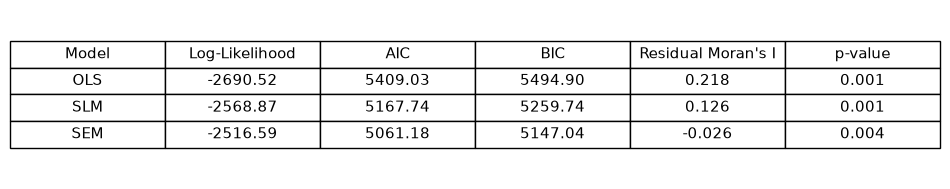

In [123]:
import matplotlib.pyplot as plt

# Format values first
comparison_display = comparison2.copy()

comparison_display["Log-Likelihood"] = comparison_display["Log-Likelihood"].map("{:.2f}".format)
comparison_display["AIC"] = comparison_display["AIC"].map("{:.2f}".format)
comparison_display["BIC"] = comparison_display["BIC"].map("{:.2f}".format)
comparison_display["Residual Moran's I"] = comparison_display["Residual Moran's I"].map("{:.3f}".format)
comparison_display["p-value"] = comparison_display["p-value"].map("{:.3f}".format)

fig, ax = plt.subplots(figsize=(12, 2.2))
ax.axis("off")

table = ax.table(
    cellText=comparison_display.values,
    colLabels=comparison_display.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

plt.savefig(
    "model_comparison2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [75]:
# Calculate Moran's I of SEM and SLM Residuals

In [76]:
moran_sar = Moran(
    sar.u.flatten(),
    w2,
    permutations=999
)

moran_sem = Moran(
    sem.u.flatten(),
    w2,
    permutations=999
)

print(
    f"SAR residual Moran's I: {moran_sar.I:.4f}, "
    f"p = {moran_sar.p_sim:.4f}"
)

print(
    f"SEM residual Moran's I: {moran_sem.I:.4f}, "
    f"p = {moran_sem.p_sim:.4f}"
)

SAR residual Moran's I: 0.1195, p = 0.0010
SEM residual Moran's I: 0.2683, p = 0.0010


In [77]:
# With public_infrastructure

In [78]:
moran_sar2 = Moran(
    sar2.u.flatten(),
    w2,
    permutations=999
)

moran_sem2 = Moran(
    sem2.u.flatten(),
    w2,
    permutations=999
)

print(
    f"SAR residual Moran's I: {moran_sar2.I:.4f}, "
    f"p = {moran_sar2.p_sim:.4f}"
)

print(
    f"SEM residual Moran's I: {moran_sem2.I:.4f}, "
    f"p = {moran_sem2.p_sim:.4f}"
)

SAR residual Moran's I: 0.1263, p = 0.0010
SEM residual Moran's I: 0.2579, p = 0.0010


In [79]:
# Check whether SEM filtered-innovation error or not

In [80]:
print(hasattr(sem, "e_filtered"))

True


In [81]:
# Calculate the unfiltered SEM one

In [82]:
moran_sem_filtered = Moran(
    sem.e_filtered.flatten(),
    w2,
    permutations=999
)

print(
    f"SEM filtered residual Moran's I: "
    f"{moran_sem_filtered.I:.4f}"
)

print(
    f"Permutation p-value: "
    f"{moran_sem_filtered.p_sim:.4f}"
)

SEM filtered residual Moran's I: -0.0234
Permutation p-value: 0.0180


In [83]:
moran_sem_filtered2 = Moran(
    sem2.e_filtered.flatten(),
    w2,
    permutations=999
)

print(
    f"SEM filtered residual Moran's I: "
    f"{moran_sem_filtered2.I:.4f}"
)

print(
    f"Permutation p-value: "
    f"{moran_sem_filtered2.p_sim:.4f}"
)

SEM filtered residual Moran's I: -0.0260
Permutation p-value: 0.0060


In [84]:
lsoa_data_connected[predictor_vars3].columns

Index(['log_accommodation_eating_and_drinking_density',
       'log_attractions_density', 'log_education_and_health_density',
       'log_manufacturing_and_production_density', 'log_retail_density',
       'log_sport_and_entertainment_density', 'log_transport_density',
       'intersection_density', 'pop_density', 'Income Rank', 'urban_part',
       'suburban_part'],
      dtype='str')

In [85]:
predictors_no_pop = [
    x for x in predictor_vars3
    if x != "pop_density"
]

X_no_pop = lsoa_data_connected[
    predictors_no_pop
].values

sem_no_pop = ML_Error(
    y,
    X_no_pop,
    w=w2,
    name_y="log_crime_density",
    name_x=predictors_no_pop,
    name_w="Queen contiguity"
)

print(sem_no_pop.summary)

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :Queen contiguity
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          12
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3394
Pseudo R-squared    :      0.9049
Log likelihood      :  -2901.7963
Sigma-square ML     :      0.3011                Akaike info criterion :    5827.593
S.E of regression   :      0.5487                Schwarz criterion     :    5901.192

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
--------------------------------------------------------------------------

In [86]:
predictors_no_pop2 = [
    x for x in predictor_vars4
    if x != "pop_density"
]

X_no_pop2 = lsoa_data_connected[
    predictors_no_pop2
].values

sem_no_pop2 = ML_Error(
    y,
    X_no_pop,
    w=w2,
    name_y="log_crime_density",
    name_x=predictors_no_pop,
    name_w="Queen contiguity"
)

print(sem_no_pop2.summary)

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :Queen contiguity
Dependent Variable  :log_crime_density                Number of Observations:        3406
Mean dependent var  :      5.5333                Number of Variables   :          12
S.D. dependent var  :      2.0348                Degrees of Freedom    :        3394
Pseudo R-squared    :      0.9049
Log likelihood      :  -2901.7963
Sigma-square ML     :      0.3011                Akaike info criterion :    5827.593
S.E of regression   :      0.5487                Schwarz criterion     :    5901.192

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
--------------------------------------------------------------------------

In [87]:
comparison_pop = pd.DataFrame({
    "Model": [
        "SEM with population density",
        "SEM without population density"
    ],
    "Log-Likelihood": [
        sem.logll,
        sem_no_pop.logll
    ],
    "AIC": [
        sem.aic,
        sem_no_pop.aic
    ],
    "BIC": [
        sem.schwarz,
        sem_no_pop.schwarz
    ]
})

comparison_pop

,Model,Log-Likelihood,AIC,BIC
0,SEM with population density,-2728.064576,5482.129153,5561.861973
1,SEM without population density,-2901.796275,5827.592550,5901.192076


In [88]:
comparison_pop2 = pd.DataFrame({
    "Model": [
        "SEM with population density",
        "SEM without population density"
    ],
    "Log-Likelihood": [
        sem2.logll,
        sem_no_pop2.logll
    ],
    "AIC": [
        sem2.aic,
        sem_no_pop2.aic
    ],
    "BIC": [
        sem2.schwarz,
        sem_no_pop2.schwarz
    ]
})

comparison_pop2

,Model,Log-Likelihood,AIC,BIC
0,SEM with population density,-2516.587635,5061.17527,5147.041384
1,SEM without population density,-2901.796275,5827.59255,5901.192076


In [89]:
# Block Model

In [90]:
control_vars = [
    "pop_density"
]

socioeconomic_vars = [
    "Income Rank"
]

built_environment_vars = [
    "log_accommodation_eating_and_drinking_density",
    "log_attractions_density",
    "log_education_and_health_density",
    "log_manufacturing_and_production_density",
    "log_public_infrastructure_density",
    "log_retail_density",
    "log_sport_and_entertainment_density",
    "log_transport_density",
    "intersection_density",
    "urban_part",
    "suburban_part"
]

In [91]:
model_0 = control_vars

model_1 = control_vars + socioeconomic_vars

model_2 = control_vars + built_environment_vars

model_3 = (
    control_vars
    + socioeconomic_vars
    + built_environment_vars
)

In [92]:
def sem_fit(var_list, model_name):

    X = lsoa_data_connected[var_list].values

    model = ML_Error(
        y,
        X,
        w=w2,
        name_y="log_crime_density",
        name_x=var_list,
        name_w="Queen contiguity",
        name_ds=model_name
    )

    return model

In [93]:
sem_0 = sem_fit(model_0, "Control")
sem_1 = sem_fit(model_1, "Socioeconomic")
sem_2 = sem_fit(model_2, "Built Environment")
sem_3 = sem_fit(model_3, "Combined")

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error


C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error


C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error


C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error


In [124]:
from esda.moran import Moran

moran_0 = Moran(sem_0.e_filtered, w2, permutations=999)
moran_1 = Moran(sem_1.e_filtered, w2, permutations=999)
moran_2 = Moran(sem_2.e_filtered, w2, permutations=999)
moran_3 = Moran(sem_3.e_filtered, w2, permutations=999)

In [139]:
model_comparison = pd.DataFrame({
    "Model": [
        "Control",
        "Socioeconomic",
        "Built Environment",
        "Combined"
    ],

    "Log-Likelihood": [
        sem_0.logll,
        sem_1.logll,
        sem_2.logll,
        sem_3.logll
    ],

    "AIC": [
        sem_0.aic,
        sem_1.aic,
        sem_2.aic,
        sem_3.aic
    ],

    # "BIC": [
    #     sem_0.schwarz,
    #     sem_1.schwarz,
    #     sem_2.schwarz,
    #     sem_3.schwarz
    # ],

    "Pseudo R2": [
        sem_0.pr2,
        sem_1.pr2,
        sem_2.pr2,
        sem_3.pr2
    ],

    "Lambda": [
        sem_0.lam,
        sem_1.lam,
        sem_2.lam,
        sem_3.lam
    ],
    "Residual Moran's I": [
        moran_0.I,
        moran_1.I,
        moran_2.I,
        moran_3.I
    ],

    # "p-value": [
    #     moran_0.p_sim,
    #     moran_1.p_sim,
    #     moran_2.p_sim,
    #     moran_3.p_sim
    # ]
})

model_comparison

,Model,Log-Likelihood,AIC,Pseudo R2,Lambda,Residual Moran's I
0,Control,-4968.711108,9941.422217,0.594306,0.737278,0.006343
1,Socioeconomic,-4610.421504,9226.843007,0.644187,0.751379,-0.004928
2,Built Environment,-2959.701166,5945.402332,0.907421,0.481076,-0.024356
3,Combined,-2516.587635,5061.175270,0.930860,0.434287,-0.025959


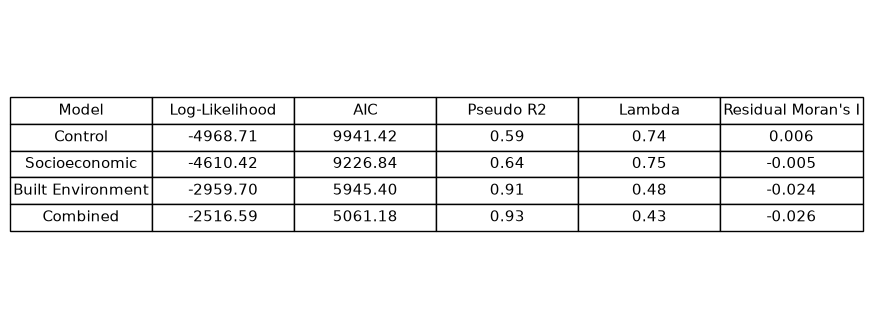

In [142]:
import matplotlib.pyplot as plt

# Format values first
comparison_display2 = model_comparison.copy()

comparison_display2["Log-Likelihood"] = comparison_display2["Log-Likelihood"].map("{:.2f}".format)
comparison_display2["AIC"] = comparison_display2["AIC"].map("{:.2f}".format)
# comparison_display2["BIC"] = comparison_display2["BIC"].map("{:.2f}".format)
comparison_display2["Pseudo R2"] = comparison_display2["Pseudo R2"].map("{:.2f}".format)
comparison_display2["Lambda"] = comparison_display2["Lambda"].map("{:.2f}".format)
comparison_display2["Residual Moran's I"] = comparison_display2["Residual Moran's I"].map("{:.3f}".format)
# comparison_display2["p-value"] = comparison_display2["p-value"].map("{:.3f}".format)

fig, ax = plt.subplots(figsize=(11, 4))
ax.axis("off")

table = ax.table(
    cellText=comparison_display2.values,
    colLabels=comparison_display2.columns,
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

plt.savefig(
    "model_comparison_blockwise.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [95]:
# Sensitivity Check for Control Variable
# Between model 3 and socio+built environment

In [96]:
socio_built = socioeconomic_vars + built_environment_vars

In [97]:
sem_socio_built = sem_fit(socio_built, "Socioeconomic+Built Environment")

C:\Users\rg25503\OneDrive - University of Bristol\Dissertation\Pycharm_Projects\.venv\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(


ML_Error


In [98]:
sensitivity_check = pd.DataFrame({
    "Model": [
        "Combined",
        "Socioeconomic+Built Environment"
        ],
    "AIC": [
        sem_3.aic,
        sem_socio_built.aic],
    "BIC": [
        sem_3.schwarz,
        sem_socio_built.schwarz]
})

sensitivity_check

,Model,AIC,BIC
0,Combined,5061.175270,5147.041384
1,Socioeconomic+Built Environment,5314.258948,5393.991768


In [99]:
moran_sem_combined = Moran(
    sem_3.u.flatten(),
    w2,
    permutations=999
)

moran_sem_socio_built = Moran(
    sem_socio_built.u.flatten(),
    w2,
    permutations=999
)

print(
    f"SEM residual Moran's I (combined): {moran_sem_combined.I:.4f}, "
    f"p = {moran_sem_combined.p_sim:.4f}"
)

print(
    f"SEM residual Moran's I (socio & built): {moran_sem_socio_built.I:.4f}, "
    f"p = {moran_sem_socio_built.p_sim:.4f}"
)

SEM residual Moran's I (combined): 0.2579, p = 0.0010
SEM residual Moran's I (socio & built): 0.3276, p = 0.0010


In [100]:
# Extract Coefficients

In [101]:
# def extract_coefs(model, model_name):
#
#     coef = pd.DataFrame({
#         "Variable": model.name_x,
#         "Beta": model.betas.flatten(),
#         "z-value": [z[0] for z in model.z_stat],
#         "p-value": [z[1] for z in model.z_stat]
#     })
#
#
#     coef["Model"] = model_name
#
#     return coef

In [102]:
def extract_coefs(model, model_name, df, y_var):

    coef = pd.DataFrame({
        "Variable": model.name_x,
        "Beta": model.betas.flatten(),
        "z-value": [z[0] for z in model.z_stat],
        "p-value": [z[1] for z in model.z_stat]
    })

    # Standard deviation of dependent variable
    y_sd = df[y_var].std()

    # Calculate standardized coefficients
    std_beta = []

    for var, beta in zip(coef["Variable"], coef["Beta"]):

        if var == "CONSTANT":
            std_beta.append(np.nan)

        elif var == "lambda":
            std_beta.append(np.nan)

        else:
            x_sd = df[var].std()
            std_beta.append(beta * (x_sd / y_sd))

    coef["Standardized Beta"] = std_beta
    coef["Model"] = model_name

    return coef

In [103]:
coef_0 = extract_coefs(
    sem_0, "Control",
    lsoa_data_connected,
    "log_crime_density"
)

coef_1 = extract_coefs(
    sem_1, "Socioeconomic",
    lsoa_data_connected,
    "log_crime_density"
)

coef_2 = extract_coefs(
    sem_2, "Built Environment",
    lsoa_data_connected,
    "log_crime_density"
)

coef_3 = extract_coefs(
    sem_3, "Combined",
    lsoa_data_connected,
    "log_crime_density"
)

coefficients = pd.concat(
    [coef_0, coef_1, coef_2, coef_3],
    ignore_index=True
)

coefficients

,Variable,Beta,z-value,p-value,Standardized Beta,Model
0,CONSTANT,4.840256,67.145711,0.000000e+00,NaN,Control
1,pop_density,0.000332,39.261170,0.000000e+00,0.507565,Control
2,lambda,0.737278,54.068998,0.000000e+00,NaN,Control
3,CONSTANT,6.276190,74.849057,0.000000e+00,NaN,Socioeconomic
4,pop_density,0.000278,35.447862,3.129260e-275,0.424820,Socioeconomic
5,Income Rank,-0.000066,-28.266928,8.816500e-176,-0.266216,Socioeconomic
6,lambda,0.751379,57.013840,0.000000e+00,NaN,Socioeconomic
7,CONSTANT,1.360471,27.927136,1.249711e-171,NaN,Built Environment
8,pop_density,0.000122,17.165467,4.815957e-66,0.186323,Built Environment
9,log_accommodation_eating_and_drinking_density,0.009524,0.745529,4.559519e-01,0.006521,Built Environment


In [105]:
# coefficients = pd.concat([
#     coef_0,
#     coef_1,
#     coef_2,
#     coef_3
# ], ignore_index=True)
#
# coefficients = add_standardized_beta(
#     coefficients,
#     lsoa_data_connected,
#     "log_crime_density"
# )

In [106]:
def sig_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

In [107]:
coefficients["Coefficient"] = (
    coefficients["Beta"].map(lambda x: f"{x:.4f}")
    + coefficients["p-value"].apply(sig_star)
)

In [108]:
coef_table = coefficients.pivot(
    index="Variable",
    columns="Model",
    values="Coefficient"
)

coef_table = coef_table[
    ["Control", "Socioeconomic", "Built Environment", "Combined"]
]

coef_table = coef_table.fillna("—")

coef_table

Model,Control,Socioeconomic,Built Environment,Combined
Variable,,,,
CONSTANT,4.8403***,6.2762***,1.3605***,2.4096***
Income Rank,—,-0.0001***,—,-0.0000***
intersection_density,—,—,0.0014***,0.0015***
lambda,0.7373***,0.7514***,0.4811***,0.4343***
log_accommodation_eating_and_drinking_density,—,—,0.0095,0.0208
log_attractions_density,—,—,0.0820***,0.0525***
log_education_and_health_density,—,—,0.0826***,0.0895***
log_manufacturing_and_production_density,—,—,-0.0397**,-0.0486***
log_public_infrastructure_density,—,—,0.6202***,0.5360***


In [143]:
coefficients["Std_Coefficient"] = (
    coefficients["Standardized Beta"].map(lambda x: f"{x:.4f}")
    + coefficients["p-value"].apply(sig_star)
)

In [144]:
coef_table2 = coefficients.pivot(
    index="Variable",
    columns="Model",
    values="Std_Coefficient"
)

coef_table2 = coef_table2[
    ["Control", "Socioeconomic", "Built Environment", "Combined"]
]

coef_table2 = coef_table2.fillna("—")

coef_table2

Model,Control,Socioeconomic,Built Environment,Combined
Variable,,,,
CONSTANT,nan***,nan***,nan***,nan***
Income Rank,—,-0.2662***,—,-0.1673***
intersection_density,—,—,0.0527***,0.0572***
lambda,nan***,nan***,nan***,nan***
log_accommodation_eating_and_drinking_density,—,—,0.0065,0.0142
log_attractions_density,—,—,0.0371***,0.0238***
log_education_and_health_density,—,—,0.0497***,0.0538***
log_manufacturing_and_production_density,—,—,-0.0199**,-0.0244***
log_public_infrastructure_density,—,—,0.3262***,0.2820***


In [ ]:
# Extra Figures

In [ ]:
# Descriptive Statistics

In [ ]:
lsoa_data_table = lsoa_data_table.rename(columns={
    "accommodation_eating_and_drinking_density":"Accommodation/Eating/Drinking",
    "attractions_density":"Attractions",
    "commercial_services_density":"Commercial Services",
    "education_and_health_density":"Education/Health",
    "manufacturing_and_production_density":"Manufacturing/Production",
    "public_infrastructure_density":"Public Infrastructure",
    "retail_density":"Retail",
    "sport_and_entertainment_density":"Sport/Entertainment",
    "transport_density":"Transport",
    "intersection_density":"Intersection Density",
    "urban_part":"Urban Proportion",
    "suburban_part":"Suburban Proportion",
    "rural_part":"Rural Proportion",
    "pop_density":"Population Density",
    "crime_density":"Crime Density"
})

In [ ]:
lsoa_data_desc3 = (
    lsoa_data_table
    .agg(["mean", "median", "std", "min", "max", "skew"])
    .T
    .round(2)
)

# Rename columns
lsoa_data_desc3.columns = [
    "Mean", "Median", "SD", "Min", "Max", "Skewness"
]

# Define groups
groups = {
    "Accommodation/Eating/Drinking": ("Built Environment", "POI Group Density"),
    "Attractions":                   ("Built Environment", "POI Group Density"),
    "Commercial Services":           ("Built Environment", "POI Group Density"),
    "Education/Health":              ("Built Environment", "POI Group Density"),
    "Manufacturing/Production":      ("Built Environment", "POI Group Density"),
    "Public Infrastructure":         ("Built Environment", "POI Group Density"),
    "Retail":                        ("Built Environment", "POI Group Density"),
    "Sport/Entertainment":           ("Built Environment", "POI Group Density"),
    "Transport":                     ("Built Environment", "POI Group Density"),

    "Intersection Density":          ("Built Environment", "Street Network"),

    "Urban Proportion":              ("Built Environment", "Spatial Signature"),
    "Suburban Proportion":           ("Built Environment", "Spatial Signature"),
    "Rural Proportion":              ("Built Environment", "Spatial Signature"),

    "Population Density":            ("Demographic", ""),

    "Income Rank":                   ("Socioeconomic Status", ""),
    "Employment Rank":               ("Socioeconomic Status", ""),

    "Crime Density":                 ("Crime", "")
}

# Add hierarchical index
lsoa_data_desc3.index = pd.MultiIndex.from_tuples(
    [groups[var] + (var,) for var in lsoa_data_desc3.index],
    names=["Group", "Subgroup", "Variable"]
)

In [ ]:
desc_export = lsoa_data_desc3.reset_index().copy()

# Identify repetitions BEFORE replacing anything
repeat_group = (
    desc_export["Group"]
    .eq(desc_export["Group"].shift())
)

repeat_subgroup = (
    repeat_group
    & desc_export["Subgroup"]
        .eq(desc_export["Subgroup"].shift())
)

# Replace repeated labels with blank strings
desc_export.loc[repeat_group, "Group"] = ""
desc_export.loc[repeat_subgroup, "Subgroup"] = ""

styled_desc = (
    desc_export.style
    .format({
        "Mean": "{:,.2f}",
        "Median": "{:,.2f}",
        "SD": "{:,.2f}",
        "Min": "{:,.2f}",
        "Max": "{:,.2f}",
        "Skewness": "{:.2f}"
    })
    .hide(axis="index")
)

dfi.export(
    styled_desc,
    "descriptive_stats.png",
    table_conversion="matplotlib",
    dpi=300
)

In [ ]:
# Before-After Histograms

In [ ]:
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns

vars_original = [
    "accommodation_eating_and_drinking_density",
    "attractions_density",
    "commercial_services_density",
    "education_and_health_density",
    "manufacturing_and_production_density",
    "public_infrastructure_density",
    "retail_density",
    "sport_and_entertainment_density",
    "transport_density",
    "crime_density"
]

vars_log = [
    "log_accommodation_eating_and_drinking_density",
    "log_attractions_density",
    "log_commercial_services_density",
    "log_education_and_health_density",
    "log_manufacturing_and_production_density",
    "log_public_infrastructure_density",
    "log_retail_density",
    "log_sport_and_entertainment_density",
    "log_transport_density",
    "log_crime_density"
]


# Planned subplot: 5 rows × 4 columns
fig, axes = plt.subplots(
    nrows=5,
    ncols=4,
    figsize=(14, 16)
)


for i, (original_var, log_var) in enumerate(
    zip(vars_original, vars_log)
):

    # Two variables per row
    row = i // 2

    # Before-after pair management
    pair = i % 2

    col_original = pair * 2
    col_log = col_original + 1

    # Original data
    original_data = lsoa_data[original_var].dropna()

    sns.histplot(
        original_data,
        bins=30,
        kde=True,
        ax=axes[row, col_original]
    )

    axes[row, col_original].set_title(
        original_var.replace("_density", "")
                    .replace("_", " ")
                    .title(),
        fontsize=9
    )

    axes[row, col_original].set_xlabel("Density")
    axes[row, col_original].set_ylabel("Number of LSOAs")

    axes[row, col_original].text(
        0.95,
        0.90,
        f"Skew = {skew(original_data):.2f}",
        transform=axes[row, col_original].transAxes,
        ha="right",
        va="top",
        fontsize=8,
        bbox=dict(
            boxstyle="round",
            facecolor="#D3D3D3",
            alpha=0.8
        )
    )


    # Log1p transformation
    log_data = lsoa_data_transformed[log_var].dropna()

    sns.histplot(
        log_data,
        bins=30,
        kde=True,
        ax=axes[row, col_log]
    )

    # Heading
    name = (
        original_var
        .replace("_density", "")
        .replace("_", " ")
        .title()
    )

    axes[row, col_original].set_title(
        f"{name} — Original",
        fontsize=9
    )

    axes[row, col_log].set_title(
        f"{name} — Log1p",
        fontsize=9
    )

    axes[row, col_log].set_xlabel("Log1p Density")
    axes[row, col_log].set_ylabel("Number of LSOAs")

    axes[row, col_log].text(
        0.95,
        0.90,
        f"Skew = {skew(log_data):.2f}",
        transform=axes[row, col_log].transAxes,
        ha="right",
        va="top",
        fontsize=8,
        bbox=dict(
            boxstyle="round",
            facecolor="#D3D3D3",
            alpha=0.8
        )
    )


plt.tight_layout(
    h_pad=2.5,
    w_pad=2
)

plt.show()

In [ ]:
save_fig(fig, "hist_before_after")